# Tier 1 scoring improvements: no retraining

**Why this notebook exists.** `docs/METRICS_IMPROVEMENT_PLAN.md` ranks five cheap changes that reuse the current predictors and the cached latents. This notebook implements all five (plan Tier 1, items 1-5), scores each one on the official test split **once**, and reports it against the current baseline with a paired-bootstrap 95% interval.

| Item | Change | Statistics fitted from |
| --- | --- | --- |
| 1 | **Per-position z-score** of the token discrepancy (196 positions, coarse and fine separately) | nominal **validation** images |
| 2 | **Per-channel standardisation** (or parameter-free layer norm) of predicted and actual latents before `1 - cos` | nominal **training** latents (layer norm: none) |
| 3 | **Gaussian smoothing** of the upsampled score map before max / top-k | nothing (sigma declared) |
| 4 | **Mahalanobis residual** score: PCA-whitened `actual - predicted` | nominal **validation** images |
| 5 | The **2x2-block** capsule predictor (`predictors_block2`) with `coarse_size = 2` | nothing (trained earlier) |

**Baseline** = baseline predictors, `adaptive` mode, default `tau = 0.5`, `lambda = 1`, **max** patch score. It is the row labelled `adaptive, default tau` in `results/calibration/pixel_metrics.csv`, and the notebook checks that it reproduces those numbers.

**Rules this notebook follows**

1. No predictor is retrained and no image is re-encoded; everything comes from the caches (a missing train/validation cache would be built, as in notebook 04).
2. Every setting is declared in the config cell *before* any test latent is scored. Nothing is chosen from test results. Rows marked `sensitivity` are for understanding, not selection.
3. **The fine-pass gate is unchanged.** Each variant only replaces the per-token score. The gate still opens on the baseline `1 - cos` region scores at `tau = 0.5`, so every variant evaluates exactly the baseline's windows and `masks/image` is identical. A paired comparison therefore isolates the scoring change.
4. A CI that contains 0 is `inconclusive`, never `improves`.

Outputs go to `results/improvements/tier1/`. Existing files are never overwritten (`OVERWRITE = False` makes the notebook stop at the start, not after the compute).

## 1. Imports and configuration

Everything you may want to change is in this cell. The "declared before looking" block is the experiment design; change it only before running, never after seeing test numbers.

In [1]:
import hashlib
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from PIL import Image

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
BASELINE_CHECKPOINTS = PROJECT_ROOT / 'checkpoints' / 'predictors'
BLOCK2_CHECKPOINTS = PROJECT_ROOT / 'checkpoints' / 'predictors_block2'
BLOCK2_CATEGORY = 'capsule'                  # the only category with a 2x2-block predictor

ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
OFFICIAL_IJEPA_ROOT = PROJECT_ROOT / 'external' / 'ijepa'
CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents'            # nominal train / val
TEST_CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents_test'
OUTPUT_ROOT = Path(os.environ.get('TIER1_OUTPUT', PROJECT_ROOT / 'results' / 'improvements' / 'tier1'))
FIGURE_ROOT = OUTPUT_ROOT / 'figures'
OVERWRITE = False
OUTPUT_FILES = (
    'variant_metrics.csv', 'bootstrap_deltas.csv', 'nominal_validation_diagnostics.csv',
    'position_bias.csv', 'tier1_summary.json',
)

MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION = float(DATA_CONFIG['nominal_split']['val_fraction'])
SPLIT_SEED = int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Declared before any test latent is scored -------------------------------------
TOP_K = 5                                    # image score variants: max (k=1) and top-5 mean
# Item 1: per-position z-score. The std of one position is estimated from only 21-39
# nominal images, so it is floored at this fraction of the median std over positions.
POSITION_STD_FLOOR_FRACTION = 0.5
# Item 2: floor on the per-channel std (guards a near-constant channel only).
CHANNEL_STD_EPS = 1e-6
# Item 3: sigma in pixels of the 224x224 upsampled map. 4 px is the plan's value. One
# token is 16 px, so 4 px is 0.25 token; PatchCore's 4 px is 0.5 token at 8 px/token,
# hence the sensitivity rows at 8 and 16 px. sigma = 0 through the same two-stage
# resampling is a control that measures the resampling alone.
SMOOTH_SIGMA_PRIMARY = 4.0
SMOOTH_SIGMA_SENSITIVITY = (8.0, 16.0)
# Item 4: one residual Gaussian shared by all 196 positions (a per-position covariance
# needs far more than 21-39 images). PCA first because 1408 dims >> samples.
MAHA_COMPONENTS_PRIMARY = 64
MAHA_COMPONENTS_SENSITIVITY = (32, 128)
MAHA_RIDGE = 1e-3                            # relative to the mean retained eigenvalue
# Item 5: coarse window of the 2x2-block predictor and of the controls.
BLOCK2_COARSE_SIZE = 2
N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 0
# -------------------------------------------------------------------------------------

if not OVERWRITE:
    existing = [OUTPUT_ROOT / name for name in OUTPUT_FILES if (OUTPUT_ROOT / name).exists()]
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')

print(f'Project: {PROJECT_ROOT}\nDevice: {DEVICE}\nOutputs: {OUTPUT_ROOT}')

Project: C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD
Device: cuda
Outputs: C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\tier1


## 2. Load splits, encoder identity and predictors

The nominal train/validation split uses the same fraction and seed as training, so the validation images are exactly those the predictors were *not* trained on. The encoder SHA-256 is checked against each checkpoint. The 2x2-block capsule predictor records the image ids it was trained and validated on; they are compared with this split to rule out leakage.

In [2]:
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, ENCODER_NAME, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import (
    MaskedLatentScorer,
    load_masking_settings,
    load_predictor_checkpoint_with_provenance,
)
from ijepa_ad.masking.score_maps import smooth_score_maps, upsample_patch_scores
from ijepa_ad.scoring import (
    ChannelStandardisedCosine,
    PositionNormaliser,
    fit_channel_stats,
    fit_mahalanobis_residual,
    layer_norm_cosine_discrepancy,
)

if not ENCODER_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Encoder checkpoint missing: {ENCODER_CHECKPOINT}')
ENCODER_SHA256 = compute_file_sha256(ENCODER_CHECKPOINT)
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
DEFAULT_TAU = MASKING_SETTINGS['threshold']
LAM = MASKING_SETTINGS['lam']
print(f'Encoder SHA-256: {ENCODER_SHA256}')
print(f'Masking settings from YAML: {MASKING_SETTINGS}')

DATASET_ROOTS = {}
for category in CATEGORIES:
    options = (
        PROJECT_ROOT / DATA_CONFIG['root'],
        PROJECT_ROOT / 'dataset',
        PROJECT_ROOT / 'dataset' / category,
    )
    root = next((r for r in options if (r / category / 'train').is_dir()), None)
    if root is None:
        raise FileNotFoundError(f'MVTec folders for {category} not found in {options}')
    DATASET_ROOTS[category] = root

SPLITS, PREDICTORS, PROVENANCE = {}, {}, {}
for category in CATEGORIES:
    train_ds, test_ds = validate_category_splits(DATASET_ROOTS[category], category)
    nominal = split_nominal_train_val(
        train_ds.samples,
        val_fraction=VAL_FRACTION,
        seed=SPLIT_SEED,
        min_train=int(DATA_CONFIG['nominal_split']['min_train']),
        min_val=int(DATA_CONFIG['nominal_split']['min_val']),
    )
    SPLITS[category] = {'train': train_ds, 'test': test_ds, 'nominal': nominal}
    path = BASELINE_CHECKPOINTS / f'{category}_cosine.pt'
    if not path.is_file():
        raise FileNotFoundError(f'Predictor checkpoint missing (no substitution): {path}')
    PREDICTORS[category], PROVENANCE[category] = load_predictor_checkpoint_with_provenance(
        path, category=category, encoder_sha256=ENCODER_SHA256, device=DEVICE
    )
    print(
        f'{category}: train={len(nominal.train)}, val={len(nominal.val)}, test={len(test_ds)}, '
        f'baseline mask_strategy={PROVENANCE[category]["mask_strategy"]}, status={PROVENANCE[category]["status"]}'
    )

BLOCK2_PATH = BLOCK2_CHECKPOINTS / f'{BLOCK2_CATEGORY}_cosine.pt'
if not BLOCK2_PATH.is_file():
    raise FileNotFoundError(f'2x2-block predictor missing (no substitution): {BLOCK2_PATH}')
BLOCK2_PREDICTOR, BLOCK2_PROVENANCE = load_predictor_checkpoint_with_provenance(
    BLOCK2_PATH, category=BLOCK2_CATEGORY, encoder_sha256=ENCODER_SHA256, device=DEVICE
)
block2_payload = torch.load(BLOCK2_PATH, map_location='cpu', weights_only=True)
nominal = SPLITS[BLOCK2_CATEGORY]['nominal']
block2_split_check = {
    'train_ids_match': set(block2_payload['cache_provenance']['train']['sample_ids']) == {s.image_id for s in nominal.train},
    'val_ids_match': set(block2_payload['cache_provenance']['val']['sample_ids']) == {s.image_id for s in nominal.val},
    'best_val_loss': block2_payload['best_val_loss'],
    'best_epoch': block2_payload['best_epoch'],
    'training_config': block2_payload['training_config'],
}
del block2_payload
if not (block2_split_check['train_ids_match'] and block2_split_check['val_ids_match']):
    raise ValueError('The 2x2-block predictor was trained on a different nominal split; its validation images would leak.')
print(f'{BLOCK2_CATEGORY} block2: split matches this notebook; mask_strategy={BLOCK2_PROVENANCE["mask_strategy"]}, '
      f'block_size={block2_split_check["training_config"]["block_size"]}, status={BLOCK2_PROVENANCE["status"]}')

Encoder SHA-256: a373c7b16165092e29bd5714c6ce79c574c4a52b01b64bf4c82dc81e6a82cf0b
Masking settings from YAML: {'coarse_size': 4, 'fine_size': 1, 'threshold': 0.5, 'lam': 1.0}
bottle: train=188, val=21, test=83, baseline mask_strategy=inference_aligned, status=complete
capsule: train=197, val=22, test=132, baseline mask_strategy=inference_aligned, status=complete
hazelnut: train=352, val=39, test=110, baseline mask_strategy=inference_aligned, status=complete
capsule block2: split matches this notebook; mask_strategy=inference_aligned, block_size=2, status=complete


## 3. Latent caches

The encoder is frozen, so every image is encoded once and cached. All three caches (nominal train, nominal validation, test) already exist locally and are only loaded. If a train/validation cache were missing it would be built here (as in notebook 04); a missing test cache stops the notebook.

In [3]:
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.caching.cli import CacheRunConfig, run_cache_generation
from ijepa_ad.caching.latent_cache import CacheNotFoundError
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset

PREPROCESSING = PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size']))
PREPROCESSING_SPEC = PreprocessingSpec.from_config(PREPROCESSING)


def expectations(category, split, samples):
    return CacheExpectations(
        category=category,
        split=split,
        encoder_name=ENCODER_NAME,
        checkpoint_sha256=ENCODER_SHA256,
        patch_size=PATCH_SIZE,
        embedding_dim=EMBEDDING_DIM,
        preprocessing=PREPROCESSING_SPEC,
        sample_ids=tuple(s.image_id for s in samples),
        num_tokens=NUM_TOKENS,
    )


def load_nominal(category, split):
    samples = getattr(SPLITS[category]['nominal'], split)
    return load_cached_latent_dataset(
        CACHE_ROOT, expectations(category, split, samples), samples=SPLITS[category]['train'].samples
    )


def load_test(category):
    return load_cached_latent_dataset(
        TEST_CACHE_ROOT,
        expectations(category, 'test', SPLITS[category]['test'].samples),
        samples=SPLITS[category]['test'].samples,
    )


missing = []
for category in CATEGORIES:
    try:
        load_nominal(category, 'train')
        load_nominal(category, 'val')
    except CacheNotFoundError:
        missing.append(category)
for category in missing:
    summary = run_cache_generation(
        CacheRunConfig(
            dataset_root=DATASET_ROOTS[category], cache_root=CACHE_ROOT, categories=(category,),
            purpose='nominal', batch_size=8, device=DEVICE, val_fraction=VAL_FRACTION, seed=SPLIT_SEED,
            image_size=PREPROCESSING.image_size, checkpoint=ENCODER_CHECKPOINT,
            official_repo=OFFICIAL_IJEPA_ROOT, encoder_name=ENCODER_NAME,
        )
    )
    if not summary.ok:
        raise RuntimeError(f'Cache build failed for {category}: {summary.to_dict()}')
print('caches built:', missing or 'none (all present)')

TRAIN_DATASETS = {c: load_nominal(c, 'train') for c in CATEGORIES}
VAL_DATASETS = {c: load_nominal(c, 'val') for c in CATEGORIES}
try:
    TEST_DATASETS = {c: load_test(c) for c in CATEGORIES}
except CacheNotFoundError as error:
    raise FileNotFoundError('The test latent cache is missing. Run notebook 03 first.') from error
for category in CATEGORIES:
    ids = [{s.image_id for s in d[category]} for d in (TRAIN_DATASETS, VAL_DATASETS, TEST_DATASETS)]
    if ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]:
        raise ValueError(f'Train/validation/test overlap in {category}')
    print(f'{category}: train={len(TRAIN_DATASETS[category])}, val={len(VAL_DATASETS[category])}, test={len(TEST_DATASETS[category])} (disjoint)')

caches built: none (all present)
bottle: train=188, val=21, test=83 (disjoint)
capsule: train=197, val=22, test=132 (disjoint)
hazelnut: train=352, val=39, test=110 (disjoint)


## Part A: fit every statistic and fix every setting (no test data)

Everything in this part uses **nominal training or validation latents only**. The test cache is not touched until Part B.

`run_scorer` is the same loop as notebook 04. Besides the scores it returns the number of masks per image and the wall-clock scoring time per image (GPU synchronised, one warm-up image excluded).

In [4]:
def run_scorer(predictor, dataset, mode, threshold=DEFAULT_TAU, *, coarse_size=None, discrepancy=None, timed=False):
    settings = {**MASKING_SETTINGS, 'threshold': float(threshold)}
    if coarse_size is not None:
        settings['coarse_size'] = int(coarse_size)
    scorer = MaskedLatentScorer(predictor, discrepancy=discrepancy, **settings)
    if timed and len(dataset):
        scorer.score(dataset[0].latent.unsqueeze(0).to(DEVICE), mode=mode)  # warm-up
    coarse, fine, work, seconds = [], [], [], 0.0
    for sample in dataset:
        latent = sample.latent.unsqueeze(0).to(DEVICE)
        if timed and DEVICE == 'cuda':
            torch.cuda.synchronize()
        started = time.perf_counter()
        result = scorer.score(latent, mode=mode)
        if timed and DEVICE == 'cuda':
            torch.cuda.synchronize()
        seconds += time.perf_counter() - started
        coarse.append(result.coarse_scores.detach().cpu())
        fine.append(result.fine_scores.detach().cpu())
        work.append(result.evaluated_regions)
    return {
        'coarse': torch.stack(coarse), 'fine': torch.stack(fine), 'work': np.asarray(work),
        'ms_per_image': 1000 * seconds / max(len(dataset), 1), 'scorer': scorer,
    }


def region_scores(scorer, coarse):
    out = torch.zeros_like(coarse)
    for window in scorer.coarse.windows():
        idx = list(window.token_indices)
        out[:, idx] = coarse[:, idx].mean(dim=1, keepdim=True)
    return out

### A1. Item 1: per-position statistics from nominal validation images

For each category, the coarse discrepancy of every token position is averaged over the nominal validation images (`fixed` mode, the coarse windows) and the fine discrepancy over a dense pass (`dense` mode, single-token windows). The ratio `std over positions of the mean / mean over positions of the std` says how large the position-dependent bias is compared with the image-to-image noise at one position. A ratio near or above 1 means the position-dependent part of the score is as large as the image-to-image noise at a fixed position, so one global threshold mixes positions with very different normal levels. The z-score also equalises the per-position spread, which this ratio does not capture.

C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(


,category,pass,val_images,mean_over_positions,std_over_positions_of_mean,mean_over_positions_of_std,position_bias_ratio
0,bottle,coarse (4x4 windows),21,0.0606,0.0478,0.0386,1.2380
1,bottle,fine (1x1 windows),21,0.0617,0.0475,0.0383,1.2392
2,capsule,coarse (4x4 windows),22,0.1260,0.0942,0.0641,1.4691
3,capsule,fine (1x1 windows),22,0.1287,0.0904,0.0639,1.4161
4,hazelnut,coarse (4x4 windows),39,0.2021,0.0848,0.0923,0.9189
5,hazelnut,fine (1x1 windows),39,0.2016,0.0834,0.0907,0.9193


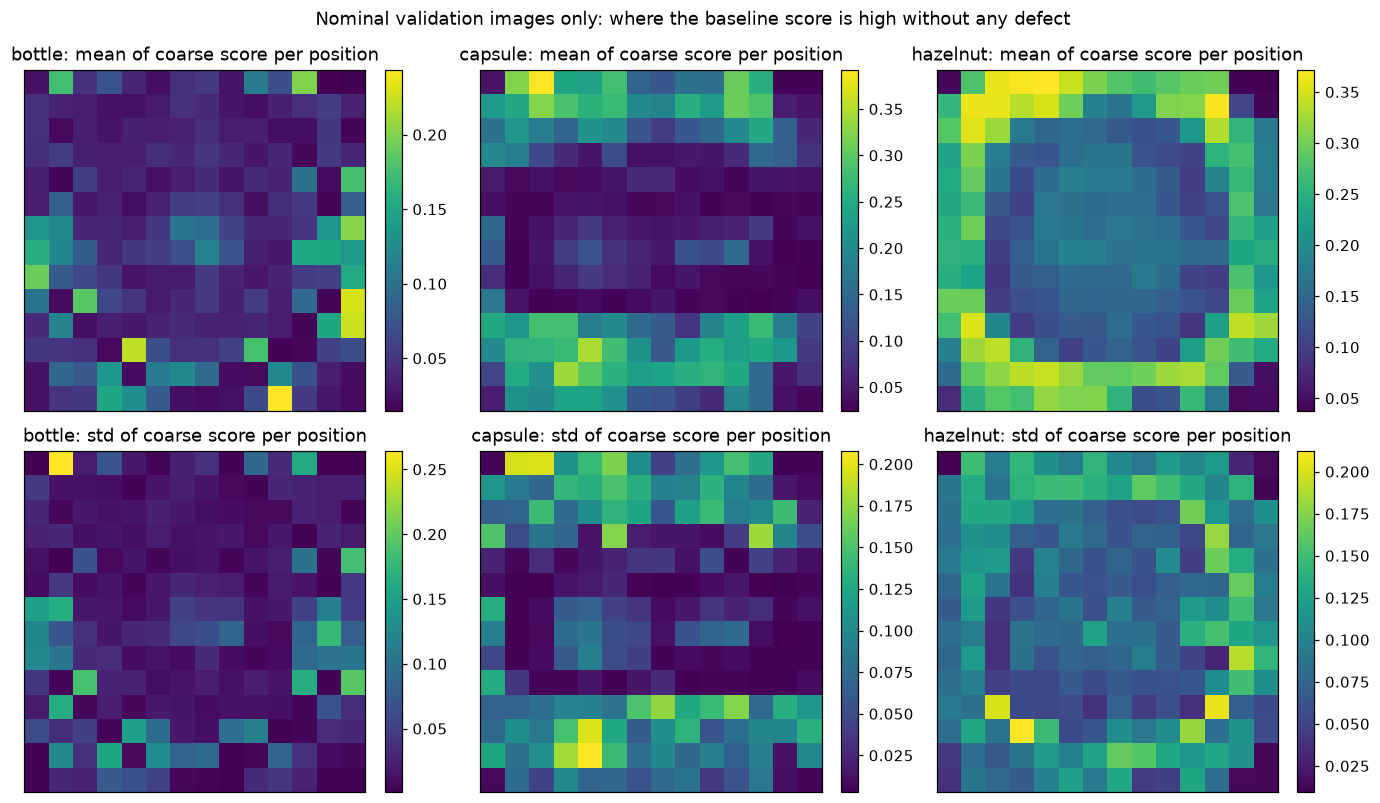

In [5]:
POSITION = {}
position_rows = []
for category in CATEGORIES:
    val = VAL_DATASETS[category]
    coarse = run_scorer(PREDICTORS[category], val, 'fixed')['coarse']
    fine = run_scorer(PREDICTORS[category], val, 'dense')['fine']
    POSITION[category] = {
        'coarse_mean': coarse.mean(0), 'coarse_std': coarse.std(0),
        'zscore': (
            PositionNormaliser.fit(coarse, divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION),
            PositionNormaliser.fit(fine, divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION),
        ),
        'center': (
            PositionNormaliser.fit(coarse, divide=False),
            PositionNormaliser.fit(fine, divide=False),
        ),
    }
    for name, scores in (('coarse (4x4 windows)', coarse), ('fine (1x1 windows)', fine)):
        position_rows.append({
            'category': category, 'pass': name, 'val_images': len(val),
            'mean_over_positions': scores.mean().item(),
            'std_over_positions_of_mean': scores.mean(0).std().item(),
            'mean_over_positions_of_std': scores.std(0).mean().item(),
            'position_bias_ratio': (scores.mean(0).std() / scores.std(0).mean()).item(),
        })
position_df = pd.DataFrame(position_rows)
display(position_df.round(4))

fig, axes = plt.subplots(2, len(CATEGORIES), figsize=(4.2 * len(CATEGORIES), 7.4))
for col, category in enumerate(CATEGORIES):
    for row, (key, title) in enumerate((('coarse_mean', 'mean'), ('coarse_std', 'std'))):
        image = axes[row, col].imshow(POSITION[category][key].reshape(14, 14).numpy(), cmap='viridis')
        axes[row, col].set_title(f'{category}: {title} of coarse score per position')
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        fig.colorbar(image, ax=axes[row, col], fraction=0.046)
fig.suptitle('Nominal validation images only: where the baseline score is high without any defect')
fig.tight_layout()
plt.show()
POSITION_FIG = fig

### A2. Item 2: per-channel statistics from nominal training latents

Mean and standard deviation of each of the 1408 channels over all tokens of all nominal **training** images. The diagnostic shows how much of the squared latent norm sits in the five largest channels before and after standardisation. If a few outlier channels dominate the raw norm, cosine similarity mostly compares those channels. The table also reports how far the tokens are from zero mean across channels (`token_channel_mean_over_std`, mean of |mean over channels| / std over channels per token). If it is near 0, layer norm only rescales and the layer-norm cosine equals the plain cosine, so variant 2b is expected to change nothing.

In [6]:
CHANNEL = {}
channel_rows = []
for category in CATEGORIES:
    train_latents = TRAIN_DATASETS[category].latents
    stats = fit_channel_stats(train_latents, eps=CHANNEL_STD_EPS)
    CHANNEL[category] = stats
    tokens = train_latents.reshape(-1, train_latents.shape[-1]).float()
    standardised = (tokens - stats.mean) / stats.std

    def top5_share(x):
        energy = x.square().mean(0)
        return (energy.topk(5).values.sum() / energy.sum()).item()

    channel_rows.append({
        'category': category, 'train_images': len(train_latents),
        'top5_channel_share_of_squared_norm_raw': top5_share(tokens),
        'top5_channel_share_after_standardising': top5_share(standardised),
        'uniform_share_for_5_of_1408': 5 / tokens.shape[-1],
        'std_max_over_median': (stats.std.max() / stats.std.median()).item(),
        'train_mean_cosine_to_mean_token_raw': F.cosine_similarity(tokens, tokens.mean(0, keepdim=True)).mean().item(),
        'token_channel_mean_over_std': (tokens.mean(1).abs() / tokens.std(1)).mean().item(),
    })
display(pd.DataFrame(channel_rows).round(4))

,category,train_images,top5_channel_share_of_squared_norm_raw,top5_channel_share_after_standardising,uniform_share_for_5_of_1408,std_max_over_median,train_mean_cosine_to_mean_token_raw,token_channel_mean_over_std
0,bottle,188,0.0810,0.0036,0.0036,52.7152,0.5556,0.0201
1,capsule,197,0.0801,0.0036,0.0036,45.5772,0.5695,0.0186
2,hazelnut,352,0.0893,0.0036,0.0036,51.2437,0.4454,0.0229


### A3. Item 4: Mahalanobis residual statistics from nominal validation images

The baseline predictor is run on the nominal validation images with the coarse windows. The residual `actual - predicted` of all 196 tokens of every image is pooled (about 4,100 to 7,600 vectors per category), centred, and reduced by PCA to `d` components; the score is the mean squared whitened coordinate, so a normal token scores about 1 and the value is unbounded above.

A held-out check guards against overfitting the covariance: the fit uses the even-indexed validation images and the score is evaluated on the odd-indexed ones (and vice versa). A mean far above 1 would mean the covariance does not generalise to unseen nominal images. It is a diagnostic only; `d` was declared above.

In [7]:
def nominal_residuals(predictor, dataset, coarse_size=None):
    settings = {**MASKING_SETTINGS}
    if coarse_size is not None:
        settings['coarse_size'] = int(coarse_size)
    scorer = MaskedLatentScorer(predictor, **settings)
    windows = scorer.coarse.windows()
    per_image = []
    for sample in dataset:
        latent = sample.latent.unsqueeze(0).to(DEVICE)
        predicted = scorer.window_predictions(latent, windows)
        per_image.append((latent[0].float() - predicted.float()).cpu())
    return torch.stack(per_image)            # [images, 196, D]


MAHALANOBIS, maha_rows = {}, []
for category in CATEGORIES:
    residuals = nominal_residuals(PREDICTORS[category], VAL_DATASETS[category])
    flat = residuals.reshape(-1, residuals.shape[-1])
    even, odd = residuals[0::2].reshape(-1, residuals.shape[-1]), residuals[1::2].reshape(-1, residuals.shape[-1])
    zero = torch.zeros(1, flat.shape[-1])
    for d in (MAHA_COMPONENTS_PRIMARY, *MAHA_COMPONENTS_SENSITIVITY):
        MAHALANOBIS[(category, d)] = fit_mahalanobis_residual(flat, n_components=d, ridge=MAHA_RIDGE)
        in_sample = MAHALANOBIS[(category, d)](zero, flat).mean().item()
        held_out = np.mean([
            fit_mahalanobis_residual(a, n_components=d, ridge=MAHA_RIDGE)(zero, b).mean().item()
            for a, b in ((even, odd), (odd, even))
        ])
        maha_rows.append({
            'category': category, 'components': d, 'residual_vectors': flat.shape[0],
            'in_sample_mean_score': in_sample, 'held_out_half_mean_score': held_out,
            'role': 'primary' if d == MAHA_COMPONENTS_PRIMARY else 'sensitivity',
        })
maha_df = pd.DataFrame(maha_rows)
display(maha_df.round(3))

,category,components,residual_vectors,in_sample_mean_score,held_out_half_mean_score,role
0,bottle,64,4116,0.997,0.986,primary
1,bottle,32,4116,0.998,0.988,sensitivity
2,bottle,128,4116,0.995,0.984,sensitivity
3,capsule,64,4312,0.996,0.972,primary
4,capsule,32,4312,0.997,0.982,sensitivity
5,capsule,128,4312,0.994,0.969,sensitivity
6,hazelnut,64,7644,0.998,0.929,primary
7,hazelnut,32,7644,0.998,0.950,sensitivity
8,hazelnut,128,7644,0.997,0.948,sensitivity


### A4. Item 5: validation check of the 2x2-block capsule predictor

The plan asks to compare the 2x2-block predictor with the baseline on validation first. Validation images are nominal, so this table can only show how well each predictor reproduces normal tokens. **A lower nominal discrepancy does not show better detection**, and nothing is selected from it. A 2x2 grid of (predictor, window size) separates the effect of the predictor from the effect of the window: the predictor trained on 2x2 blocks is also run with 4x4 windows, and the baseline predictor with 2x2 windows.

In [8]:
CAPSULE_CELLS = {   # name -> (predictor, coarse window)
    'baseline predictor, 4x4 windows (= baseline)': (PREDICTORS[BLOCK2_CATEGORY], 4),
    'baseline predictor, 2x2 windows (control)': (PREDICTORS[BLOCK2_CATEGORY], BLOCK2_COARSE_SIZE),
    '2x2-block predictor, 4x4 windows (control)': (BLOCK2_PREDICTOR, 4),
    '2x2-block predictor, 2x2 windows (item 5)': (BLOCK2_PREDICTOR, BLOCK2_COARSE_SIZE),
}
val_rows = []
for name, (predictor, size) in CAPSULE_CELLS.items():
    coarse = run_scorer(predictor, VAL_DATASETS[BLOCK2_CATEGORY], 'fixed', coarse_size=size)['coarse']
    val_rows.append({
        'category': BLOCK2_CATEGORY, 'config': name, 'coarse_window': size,
        'val_mean_token_score': coarse.mean().item(),
        'val_p99_token_score': coarse.flatten().quantile(0.99).item(),
        'val_mean_of_image_max': coarse.max(1).values.mean().item(),
    })
block2_val_df = pd.DataFrame(val_rows)
display(block2_val_df.round(4))
print('block2 checkpoint:', {k: block2_split_check[k] for k in ('train_ids_match', 'val_ids_match', 'best_epoch', 'best_val_loss')})

block2 checkpoint: {'train_ids_match': True, 'val_ids_match': True, 'best_epoch': 74, 'best_val_loss': 0.12247512421824715}


,category,config,coarse_window,val_mean_token_score,val_p99_token_score,val_mean_of_image_max
0,capsule,"baseline predictor, 4x4 windows (= baseline)",4,0.1260,0.5433,0.6817
1,capsule,"baseline predictor, 2x2 windows (control)",2,0.1276,0.5420,0.6696
2,capsule,"2x2-block predictor, 4x4 windows (control)",4,0.1292,0.5170,0.6312
3,capsule,"2x2-block predictor, 2x2 windows (item 5)",2,0.1246,0.5080,0.5806


### A5. Declared design, frozen

The summary below is what Part B will run. It is written into the saved JSON too. Nothing after this point depends on a test result.

In [9]:
DECLARED = {
    'baseline': 'baseline predictors, adaptive mode, default tau, lambda from YAML, max patch score',
    'masking_settings_yaml': MASKING_SETTINGS,
    'fine_gate': 'unchanged: opens on baseline 1-cos region scores at the default tau; every variant evaluates the baseline windows',
    'top_k': TOP_K,
    'item1_position_zscore': {
        'stats_from': 'nominal validation images only',
        'coarse_stats_from_mode': 'fixed (4x4 windows)', 'fine_stats_from_mode': 'dense (1x1 windows)',
        'std_floor_fraction_of_median_std': POSITION_STD_FLOOR_FRACTION,
        'fused': 'z_coarse + lambda * fired * z_fine, fired = region score >= tau',
        'ablation': 'centre only (subtract per-position mean, no division)',
    },
    'item2_channel': {
        'stats_from': 'nominal training latents only', 'std_eps': CHANNEL_STD_EPS,
        'variants': ['per-channel standardisation then 1-cos', 'parameter-free layer norm then 1-cos'],
    },
    'item3_smoothing': {
        'sigma_primary_px_on_224_map': SMOOTH_SIGMA_PRIMARY, 'sigma_sensitivity': list(SMOOTH_SIGMA_SENSITIVITY),
        'control': 'sigma 0 through the same two-stage resampling',
        'image_score': 'smoothed map sampled at the 196 token centres, then max / top-k',
        'pixel_maps': '14x14 -> 224x224 bilinear, Gaussian blur, 224x224 -> ground-truth size bilinear',
    },
    'item4_mahalanobis': {
        'stats_from': 'nominal validation images only', 'covariance': 'one shared Gaussian over all positions',
        'components_primary': MAHA_COMPONENTS_PRIMARY, 'components_sensitivity': list(MAHA_COMPONENTS_SENSITIVITY),
        'ridge_relative_to_mean_eigenvalue': MAHA_RIDGE,
        'fitted_on': 'coarse-window residuals; the same model scores fine windows (they rarely fire at tau 0.5)',
    },
    'item5_block2': {
        'predictor': str(BLOCK2_PATH.relative_to(PROJECT_ROOT)), 'coarse_size': BLOCK2_COARSE_SIZE,
        'controls': [n for n in CAPSULE_CELLS if 'control' in n],
    },
    'bootstrap': {'n': N_BOOTSTRAP, 'seed': BOOTSTRAP_SEED, 'unit': 'test images, good and anomalous resampled separately, paired across variants'},
}
print(json.dumps(DECLARED, indent=2))

{
  "baseline": "baseline predictors, adaptive mode, default tau, lambda from YAML, max patch score",
  "masking_settings_yaml": {
    "coarse_size": 4,
    "fine_size": 1,
    "threshold": 0.5,
    "lam": 1.0
  },
  "fine_gate": "unchanged: opens on baseline 1-cos region scores at the default tau; every variant evaluates the baseline windows",
  "top_k": 5,
  "item1_position_zscore": {
    "stats_from": "nominal validation images only",
    "coarse_stats_from_mode": "fixed (4x4 windows)",
    "fine_stats_from_mode": "dense (1x1 windows)",
    "std_floor_fraction_of_median_std": 0.5,
    "fused": "z_coarse + lambda * fired * z_fine, fired = region score >= tau",
    "ablation": "centre only (subtract per-position mean, no division)"
  },
  "item2_channel": {
    "stats_from": "nominal training latents only",
    "std_eps": 1e-06,
    "variants": [
      "per-channel standardisation then 1-cos",
      "parameter-free layer norm then 1-cos"
    ]
  },
  "item3_smoothing": {
    "sigma_pr

## Part B: score the test split once

For each category the baseline is scored first, with timing. Then each variant is scored on the same test latents:

* **Items 2 and 4** need a new pass with a different discrepancy (`MaskedLatentScorer(discrepancy=...)`). The windows and the gate are unchanged, so the notebook asserts that `masks/image` equals the baseline's.
* **Items 1 and 3** are post-hoc transformations of the baseline's raw coarse and fine scores, so they reuse the baseline pass.
* **Item 5** (capsule only) changes the predictor and the window size, so it has its own passes.

`scores_from` in the output tables says which pass produced each row's scores.

In [10]:
def load_ground_truth(annotation):
    if annotation.mask_path is None:
        with Image.open(annotation.image_path) as image:
            width, height = image.size
        return np.zeros((height, width), dtype=bool)
    with Image.open(annotation.mask_path) as mask_image:
        return np.asarray(mask_image.convert('L')) > 0


TEST = {}
for category in CATEGORIES:
    dataset = TEST_DATASETS[category]
    labels = np.asarray([int(s.annotation.label != 'good') for s in dataset])
    masks = [load_ground_truth(s.annotation) for s in dataset]
    TEST[category] = {'labels': labels, 'masks': masks}
    print(f'{category}: {len(labels)} test images ({int(labels.sum())} anomalous)')

VARIANTS = {c: {} for c in CATEGORIES}   # category -> name -> dict(patch, sigma, work, ms, item, role, scores_from)


def add_variant(category, name, *, item, role, patch, work, ms, scores_from, n_coarse, sigma=None):
    VARIANTS[category][name] = {
        'patch': patch, 'sigma': sigma, 'work': np.asarray(work), 'ms': ms, 'n_coarse': n_coarse,
        'item': item, 'role': role, 'scores_from': scores_from,
    }


RAW = {}
for category in CATEGORIES:
    started = time.perf_counter()
    dataset = TEST_DATASETS[category]
    predictor = PREDICTORS[category]
    base = run_scorer(predictor, dataset, 'adaptive', timed=True)
    n_coarse = len(base['scorer'].coarse.windows())
    fired = region_scores(base['scorer'], base['coarse']) >= DEFAULT_TAU
    if not np.array_equal(fired.sum(1).numpy() + n_coarse, base['work']):
        raise AssertionError('recomputed fine gate disagrees with the scorer')
    RAW[category] = {'coarse': base['coarse'], 'fine': base['fine'], 'fired': fired, 'work': base['work'], 'ms': base['ms_per_image']}
    add_variant(category, 'baseline', item='-', role='baseline', patch=base['coarse'] + LAM * base['fine'],
                work=base['work'], ms=base['ms_per_image'], scores_from='baseline pass', n_coarse=n_coarse)

    # ---- item 1: per-position normalisation, post hoc on the baseline pass ----
    for name, key, label in (('1a_position_zscore', 'zscore', 'primary'), ('1b_position_centre_only', 'center', 'ablation')):
        norm_coarse, norm_fine = POSITION[category][key]
        patch = norm_coarse.apply(base['coarse']) + LAM * fired.float() * norm_fine.apply(base['fine'])
        add_variant(category, name, item='1', role=label, patch=patch, work=base['work'],
                    ms=base['ms_per_image'], scores_from='baseline pass (post hoc)', n_coarse=n_coarse)

    # ---- items 2 and 4: new discrepancy, same windows and gate ----
    scorer_variants = [
        ('2a_channel_standardise', '2', 'primary', ChannelStandardisedCosine(CHANNEL[category])),
        ('2b_layer_norm', '2', 'primary', layer_norm_cosine_discrepancy),
    ]
    for d in (MAHA_COMPONENTS_PRIMARY, *MAHA_COMPONENTS_SENSITIVITY):
        scorer_variants.append((
            f'4_mahalanobis_d{d}', '4', 'primary' if d == MAHA_COMPONENTS_PRIMARY else 'sensitivity',
            MAHALANOBIS[(category, d)],
        ))
    for name, item, role, discrepancy in scorer_variants:
        run = run_scorer(predictor, dataset, 'adaptive', discrepancy=discrepancy, timed=True)
        if not np.array_equal(run['work'], base['work']):
            raise AssertionError(f'{name}: windows evaluated differ from the baseline')
        add_variant(category, name, item=item, role=role, patch=run['coarse'] + LAM * run['fine'],
                    work=run['work'], ms=run['ms_per_image'], scores_from='own pass', n_coarse=n_coarse)

    # ---- item 3: smoothing, post hoc on the baseline patch scores ----
    smoothing = [('3_smooth_sigma0_control', 0.0, 'control'), (f'3_smooth_sigma{SMOOTH_SIGMA_PRIMARY:g}', SMOOTH_SIGMA_PRIMARY, 'primary')]
    smoothing += [(f'3_smooth_sigma{s:g}', s, 'sensitivity') for s in SMOOTH_SIGMA_SENSITIVITY]
    for name, sigma, role in smoothing:
        add_variant(category, name, item='3', role=role, patch=VARIANTS[category]['baseline']['patch'], work=base['work'],
                    ms=base['ms_per_image'], scores_from='baseline pass (post hoc)', n_coarse=n_coarse, sigma=sigma)

    # ---- item 5: 2x2-block capsule predictor and its controls ----
    if category == BLOCK2_CATEGORY:
        for name, key, (cell_predictor, size), item, role in (
            ('5_block2_predictor_2x2_windows', '2x2-block predictor, 2x2 windows (item 5)', CAPSULE_CELLS['2x2-block predictor, 2x2 windows (item 5)'], '5', 'primary'),
            ('5c_baseline_predictor_2x2_windows', 'baseline predictor, 2x2 windows (control)', CAPSULE_CELLS['baseline predictor, 2x2 windows (control)'], '5', 'control'),
            ('5c_block2_predictor_4x4_windows', '2x2-block predictor, 4x4 windows (control)', CAPSULE_CELLS['2x2-block predictor, 4x4 windows (control)'], '5', 'control'),
        ):
            run = run_scorer(cell_predictor, dataset, 'adaptive', coarse_size=size, timed=True)
            add_variant(category, name, item=item, role=role, patch=run['coarse'] + LAM * run['fine'],
                        work=run['work'], ms=run['ms_per_image'], scores_from=f'own pass ({key})',
                        n_coarse=len(run['scorer'].coarse.windows()))
    print(f'{category}: {len(VARIANTS[category])} variants scored in {time.perf_counter() - started:.0f}s; '
          f'baseline masks/image={base["work"].mean():.2f}, fine pass fired on {100 * (base["work"] > n_coarse).mean():.1f}% of test images')

bottle: 83 test images (63 anomalous)
capsule: 132 test images (109 anomalous)
hazelnut: 110 test images (70 anomalous)
bottle: 12 variants scored in 12s; baseline masks/image=16.19, fine pass fired on 1.2% of test images
capsule: 15 variants scored in 40s; baseline masks/image=16.00, fine pass fired on 0.0% of test images
hazelnut: 12 variants scored in 17s; baseline masks/image=16.15, fine pass fired on 0.9% of test images


## Evaluation

* **Image score**: `max` (k = 1) and the mean of the `top-5` patch scores.
* **Pixel maps**: the patch scores are bilinearly upsampled straight to the ground-truth size, exactly as in notebook 04. For the smoothing rows the path is 14x14 to 224x224, Gaussian blur, then 224x224 to the ground-truth size, and the image score is read from the smoothed map at the 196 token centres. The `sigma = 0` control runs that two-stage path without blurring, so any difference between it and the baseline is due to the resampling alone.
* **Pixel AUROC and AUPRO** use the same functions and settings as notebook 03/04 (AUPRO: 200 thresholds, FPR limit 0.3).

In [11]:
def centre_samples(maps224):
    # value of the 224x224 map at each token centre (average of the 2x2 pixels around it)
    return F.avg_pool2d(maps224[:, :, 7:, 7:], kernel_size=2, stride=16).flatten(1)


def top_k_mean(scores, k):
    return scores.topk(k, dim=1).values.mean(dim=1).numpy()


def evaluate_variant(category, variant):
    labels, masks = TEST[category]['labels'], TEST[category]['masks']
    patch = variant['patch']
    if variant['sigma'] is None:
        token_scores = patch
        maps = [upsample_patch_scores(p, output_size=m.shape)[0, 0].numpy().astype(np.float32) for p, m in zip(patch, masks)]
    else:
        smoothed = smooth_score_maps(upsample_patch_scores(patch, output_size=224), variant['sigma'])
        token_scores = centre_samples(smoothed)
        maps = [
            F.interpolate(smoothed[i:i + 1], size=m.shape, mode='bilinear', align_corners=False)[0, 0].numpy().astype(np.float32)
            for i, m in enumerate(masks)
        ]
    scores = {'max': token_scores.max(dim=1).values.numpy(), 'top5': top_k_mean(token_scores, TOP_K)}
    return {
        'scores': scores,
        'image_auroc_max': image_auroc(labels, scores['max']),
        'image_auroc_top5': image_auroc(labels, scores['top5']),
        'pixel_auroc': pixel_auroc(maps, masks),
        'aupro': aupro(maps, masks, num_thresholds=200),
    }


# the sigma = 0 two-stage path must reproduce the patch values at the token centres
check = VARIANTS['bottle']['3_smooth_sigma0_control']['patch'][:3]
centre = centre_samples(upsample_patch_scores(check, output_size=224))
print(f'token-centre sampling check (sigma 0): max |sampled - patch| = {(centre - check).abs().max().item():.2e} '
      f'(patch score range {check.max().item() - check.min().item():.2f})')

RESULTS = {}
for category in CATEGORIES:
    started = time.perf_counter()
    for name, variant in VARIANTS[category].items():
        RESULTS[(category, name)] = evaluate_variant(category, variant)
    print(f'{category}: evaluated {len(VARIANTS[category])} variants in {time.perf_counter() - started:.0f}s')

token-centre sampling check (sigma 0): max |sampled - patch| = 3.24e-02 (patch score range 0.78)
bottle: evaluated 12 variants in 207s
capsule: evaluated 15 variants in 422s
hazelnut: evaluated 12 variants in 327s


### Does the baseline row reproduce notebook 04?

The baseline must match the numbers already saved under `results/calibration/` (`adaptive, default tau`, `lambda = 1`). If it did not, every delta below would be measured against a different baseline.

In [12]:
saved_pixel = pd.read_csv(PROJECT_ROOT / 'results' / 'calibration' / 'pixel_metrics.csv')
saved_grid = pd.read_csv(PROJECT_ROOT / 'results' / 'calibration' / 'image_auroc_grid.csv')
repro_rows = []
for category in CATEGORIES:
    mine = RESULTS[(category, 'baseline')]
    pixel = saved_pixel[(saved_pixel.category == category) & (saved_pixel.config == 'adaptive, default tau')].iloc[0]
    grid = saved_grid[(saved_grid.category == category) & (saved_grid.gate == 'default') & (saved_grid['lambda'] == 1.0)].set_index('k')
    for metric, value, saved in (
        ('image_auroc_max', mine['image_auroc_max'], grid.loc[1, 'image_auroc']),
        ('image_auroc_top5', mine['image_auroc_top5'], grid.loc[5, 'image_auroc']),
        ('pixel_auroc', mine['pixel_auroc'], pixel['pixel_auroc']),
        ('aupro', mine['aupro'], pixel['aupro']),
        ('masks_per_image', float(VARIANTS[category]['baseline']['work'].mean()), pixel['masks_per_image']),
    ):
        repro_rows.append({'category': category, 'metric': metric, 'this_notebook': value, 'results/calibration': saved, 'abs_diff': abs(value - saved)})
repro_df = pd.DataFrame(repro_rows)
display(repro_df.round(6))
BASELINE_REPRODUCED = bool((repro_df.abs_diff < 1e-4).all())
print('baseline reproduces results/calibration:', BASELINE_REPRODUCED)
if not BASELINE_REPRODUCED:
    raise AssertionError('The baseline does not reproduce notebook 04; do not compare against it.')

baseline reproduces results/calibration: True


,category,metric,this_notebook,results/calibration,abs_diff
0,bottle,image_auroc_max,0.924603,0.924603,0.0
1,bottle,image_auroc_top5,0.956349,0.956349,0.0
2,bottle,pixel_auroc,0.929522,0.929522,0.0
3,bottle,aupro,0.765731,0.765731,0.0
4,bottle,masks_per_image,16.192771,16.192771,0.0
5,capsule,image_auroc_max,0.521739,0.521739,0.0
6,capsule,image_auroc_top5,0.527722,0.527722,0.0
7,capsule,pixel_auroc,0.684478,0.684478,0.0
8,capsule,aupro,0.098093,0.098093,0.0
9,capsule,masks_per_image,16.000000,16.000000,0.0


## Paired bootstrap

The test images are resampled with replacement 1,000 times, good and anomalous images separately, with the **same resampled index set for every variant** (seed 0, the same stream as notebook 04). For every resample the image AUROC of the variant and of the reference is computed on the same images; the 2.5th and 97.5th percentiles of the difference are the 95% interval.

* The primary reference is the **baseline `max` score**, as requested. For `top-5` rows a like-for-like reference (baseline `top-5`) is added, so a top-k effect is not credited to the variant. The smoothing rows get a third reference, the `sigma = 0` control, which isolates the blur from the two-stage resampling.
* Verdict wording matches `results/calibration/bootstrap_deltas.csv`: `improves` if the whole interval is above 0, `worsens` if it is below 0, otherwise `inconclusive (CI contains 0)`.
* The intervals are for **image AUROC**. Pixel AUROC and AUPRO below are point estimates without an interval.

In [13]:
def bootstrap_indices(labels, n=N_BOOTSTRAP, seed=BOOTSTRAP_SEED):
    rng = np.random.default_rng(seed)
    positives, negatives = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
    return [
        np.concatenate([rng.choice(positives, len(positives)), rng.choice(negatives, len(negatives))])
        for _ in range(n)
    ]


def boot_aurocs(labels, scores, indices):
    return np.asarray([image_auroc(labels[idx], scores[idx]) for idx in indices])


def verdict(low, high):
    return 'improves' if low > 0 else 'worsens' if high < 0 else 'inconclusive (CI contains 0)'


boot_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    indices = bootstrap_indices(labels)
    cache = {}

    def boot(name, key):
        if (name, key) not in cache:
            cache[(name, key)] = boot_aurocs(labels, RESULTS[(category, name)]['scores'][key], indices)
        return cache[(name, key)]

    for name, variant in VARIANTS[category].items():
        for score_key, score_label in (('max', 'max'), ('top5', f'top-{TOP_K}')):
            if name == 'baseline' and score_key == 'max':
                continue
            # (reference variant, reference score key, label); the first is the requested comparison
            references = [('baseline', 'max', 'baseline, max score')]
            if score_key == 'top5':
                references.append(('baseline', 'top5', 'baseline, same score'))
            if variant['item'] == '3' and variant['sigma']:
                references.append(('3_smooth_sigma0_control', score_key, 'sigma-0 control, same score'))
            auroc = RESULTS[(category, name)][f'image_auroc_{score_key}']
            for ref_name, ref_key, ref_label in references:
                ref_auroc = RESULTS[(category, ref_name)][f'image_auroc_{ref_key}']
                deltas = boot(name, score_key) - boot(ref_name, ref_key)
                low, high = np.percentile(deltas, [2.5, 97.5])
                boot_rows.append({
                    'category': category, 'variant': name, 'item': variant['item'], 'role': variant['role'],
                    'image_score': score_label, 'reference': ref_label, 'image_auroc': auroc,
                    'reference_auroc': ref_auroc, 'delta_image_auroc': auroc - ref_auroc,
                    'ci95_low': low, 'ci95_high': high, 'verdict': verdict(low, high),
                })
boot_df = pd.DataFrame(boot_rows)

# bootstrap sanity check against notebook 04: "top-5 only (default tau)" is baseline top-5 vs baseline max
saved_boot = pd.read_csv(PROJECT_ROOT / 'results' / 'calibration' / 'bootstrap_deltas.csv')
saved_top5 = saved_boot[saved_boot['change vs original'] == 'top-5 only (default tau)'].set_index('category')
mine_top5 = boot_df[(boot_df.variant == 'baseline') & (boot_df.image_score == f'top-{TOP_K}') & (boot_df.reference == 'baseline, max score')].set_index('category')
BOOTSTRAP_MATCHES_NB04 = all(
    abs(mine_top5.loc[c, col] - saved_top5.loc[c, saved_col]) < 1e-9
    for c in CATEGORIES for col, saved_col in (('delta_image_auroc', 'delta_image_auroc'), ('ci95_low', 'ci95_low'), ('ci95_high', 'ci95_high'))
)
print('bootstrap procedure reproduces notebook 04 (top-5 only, default tau):', BOOTSTRAP_MATCHES_NB04)

bootstrap procedure reproduces notebook 04 (top-5 only, default tau): True


## Results

### Main table: every variant, every metric

`d pixel AUROC` and `d AUPRO` are differences from the baseline row of the same category (point estimates). `masks/image` is identical across items 1-4 by construction; only item 5 changes it.

In [14]:
metric_rows = []
for category in CATEGORIES:
    base = RESULTS[(category, 'baseline')]
    for name, variant in VARIANTS[category].items():
        r = RESULTS[(category, name)]
        metric_rows.append({
            'category': category, 'variant': name, 'item': variant['item'], 'role': variant['role'],
            'image_auroc_max': r['image_auroc_max'], 'image_auroc_top5': r['image_auroc_top5'],
            'pixel_auroc': r['pixel_auroc'], 'aupro': r['aupro'],
            'd_pixel_auroc': r['pixel_auroc'] - base['pixel_auroc'], 'd_aupro': r['aupro'] - base['aupro'],
            'coarse_masks': variant['n_coarse'], 'masks_per_image': float(variant['work'].mean()),
            'fine_trigger_rate': float(np.mean(variant['work'] > variant['n_coarse'])),
            'scorer_ms_per_image': variant['ms'], 'scores_from': variant['scores_from'],
        })
metrics_df = pd.DataFrame(metric_rows)
for category in CATEGORIES:
    print(f'\n{category}')
    display(metrics_df[metrics_df.category == category].drop(columns=['category', 'scores_from']).round(4).reset_index(drop=True))


bottle

capsule

hazelnut


,variant,item,role,image_auroc_max,image_auroc_top5,pixel_auroc,aupro,d_pixel_auroc,d_aupro,coarse_masks,masks_per_image,fine_trigger_rate,scorer_ms_per_image
0,baseline,-,baseline,0.9246,0.9563,0.9295,0.7657,0.0000,0.0000,16,16.1928,0.012,21.8457
1,1a_position_zscore,1,primary,0.9929,0.9984,0.9524,0.8309,0.0229,0.0652,16,16.1928,0.012,21.8457
2,1b_position_centre_only,1,ablation,0.9302,0.9794,0.9496,0.8171,0.0200,0.0514,16,16.1928,0.012,21.8457
3,2a_channel_standardise,2,primary,0.7706,0.9373,0.8692,0.5519,-0.0604,-0.2138,16,16.1928,0.012,22.8432
4,2b_layer_norm,2,primary,0.9246,0.9563,0.9295,0.7657,-0.0000,-0.0000,16,16.1928,0.012,22.8743
5,4_mahalanobis_d64,4,primary,0.9794,0.9897,0.9429,0.8148,0.0133,0.0491,16,16.1928,0.012,22.5186
6,4_mahalanobis_d32,4,sensitivity,0.8976,0.9532,0.8664,0.6935,-0.0631,-0.0722,16,16.1928,0.012,22.3106
7,4_mahalanobis_d128,4,sensitivity,0.9968,0.9952,0.9638,0.8474,0.0343,0.0817,16,16.1928,0.012,23.4085
8,3_smooth_sigma0_control,3,control,0.9294,0.9595,0.9296,0.7659,0.0001,0.0001,16,16.1928,0.012,21.8457
9,3_smooth_sigma4,3,primary,0.9579,0.9714,0.9331,0.7723,0.0036,0.0066,16,16.1928,0.012,21.8457


,variant,item,role,image_auroc_max,image_auroc_top5,pixel_auroc,aupro,d_pixel_auroc,d_aupro,coarse_masks,masks_per_image,fine_trigger_rate,scorer_ms_per_image
0,baseline,-,baseline,0.5217,0.5277,0.6845,0.0981,0.0000,0.0000,16,16.0000,0.0000,22.0870
1,1a_position_zscore,1,primary,0.6223,0.6905,0.9011,0.5080,0.2167,0.4099,16,16.0000,0.0000,22.0870
2,1b_position_centre_only,1,ablation,0.4838,0.6454,0.8634,0.3638,0.1790,0.2657,16,16.0000,0.0000,22.0870
3,2a_channel_standardise,2,primary,0.4675,0.5413,0.7715,0.1306,0.0870,0.0325,16,16.0000,0.0000,22.9305
4,2b_layer_norm,2,primary,0.5217,0.5285,0.6844,0.0981,-0.0000,-0.0000,16,16.0000,0.0000,22.6513
5,4_mahalanobis_d64,4,primary,0.4826,0.6091,0.8732,0.3446,0.1887,0.2465,16,16.0000,0.0000,22.1116
6,4_mahalanobis_d32,4,sensitivity,0.5616,0.5967,0.7038,0.1654,0.0193,0.0673,16,16.0000,0.0000,22.8259
7,4_mahalanobis_d128,4,sensitivity,0.6023,0.6526,0.9126,0.4596,0.2282,0.3615,16,16.0000,0.0000,23.2772
8,3_smooth_sigma0_control,3,control,0.5166,0.5158,0.6844,0.0979,-0.0001,-0.0002,16,16.0000,0.0000,22.0870
9,3_smooth_sigma4,3,primary,0.5102,0.4719,0.6789,0.0871,-0.0056,-0.0110,16,16.0000,0.0000,22.0870


,variant,item,role,image_auroc_max,image_auroc_top5,pixel_auroc,aupro,d_pixel_auroc,d_aupro,coarse_masks,masks_per_image,fine_trigger_rate,scorer_ms_per_image
0,baseline,-,baseline,0.8021,0.9304,0.9067,0.5774,0.0000,0.0000,16,16.1455,0.0091,29.1139
1,1a_position_zscore,1,primary,0.8643,0.9529,0.9692,0.8118,0.0625,0.2344,16,16.1455,0.0091,29.1139
2,1b_position_centre_only,1,ablation,0.8221,0.9539,0.9642,0.7878,0.0574,0.2104,16,16.1455,0.0091,29.1139
3,2a_channel_standardise,2,primary,0.6739,0.8250,0.9012,0.4720,-0.0056,-0.1054,16,16.1455,0.0091,24.1747
4,2b_layer_norm,2,primary,0.8021,0.9307,0.9068,0.5773,0.0000,-0.0001,16,16.1455,0.0091,23.9228
5,4_mahalanobis_d64,4,primary,0.7354,0.8336,0.8985,0.6024,-0.0082,0.0249,16,16.1455,0.0091,23.8648
6,4_mahalanobis_d32,4,sensitivity,0.5939,0.7404,0.7932,0.4595,-0.1135,-0.1179,16,16.1455,0.0091,23.0341
7,4_mahalanobis_d128,4,sensitivity,0.9343,0.9446,0.9581,0.7728,0.0514,0.1954,16,16.1455,0.0091,23.4243
8,3_smooth_sigma0_control,3,control,0.8175,0.9332,0.9068,0.5776,0.0001,0.0001,16,16.1455,0.0091,29.1139
9,3_smooth_sigma4,3,primary,0.8754,0.9457,0.9119,0.5871,0.0052,0.0097,16,16.1455,0.0091,29.1139


### Paired-bootstrap deltas (image AUROC)

`reference = baseline, max score` is the comparison requested. For `top-5` rows, `baseline, same score` removes the part of the gain that top-k alone already gave in notebook 04.

In [15]:
shown = boot_df.copy()
shown['CI95'] = shown.apply(lambda r: f'[{r.ci95_low:+.3f}, {r.ci95_high:+.3f}]', axis=1)
columns = ['variant', 'role', 'image_score', 'reference', 'image_auroc', 'delta_image_auroc', 'CI95', 'verdict']
for category in CATEGORIES:
    print(f'\n{category}')
    display(shown[shown.category == category][columns].round(4).reset_index(drop=True))


bottle

capsule

hazelnut


,variant,role,image_score,reference,image_auroc,delta_image_auroc,CI95,verdict
0,baseline,baseline,top-5,"baseline, max score",0.9563,0.0317,"[-0.005, +0.078]",inconclusive (CI contains 0)
1,baseline,baseline,top-5,"baseline, same score",0.9563,0.0000,"[+0.000, +0.000]",inconclusive (CI contains 0)
2,1a_position_zscore,primary,max,"baseline, max score",0.9929,0.0683,"[+0.013, +0.145]",improves
3,1a_position_zscore,primary,top-5,"baseline, max score",0.9984,0.0738,"[+0.021, +0.152]",improves
4,1a_position_zscore,primary,top-5,"baseline, same score",0.9984,0.0421,"[+0.010, +0.092]",improves
5,1b_position_centre_only,ablation,max,"baseline, max score",0.9302,0.0056,"[-0.045, +0.068]",inconclusive (CI contains 0)
6,1b_position_centre_only,ablation,top-5,"baseline, max score",0.9794,0.0548,"[+0.010, +0.117]",improves
7,1b_position_centre_only,ablation,top-5,"baseline, same score",0.9794,0.0230,"[+0.003, +0.056]",improves
8,2a_channel_standardise,primary,max,"baseline, max score",0.7706,-0.1540,"[-0.271, -0.048]",worsens
9,2a_channel_standardise,primary,top-5,"baseline, max score",0.9373,0.0127,"[-0.040, +0.069]",inconclusive (CI contains 0)


,variant,role,image_score,reference,image_auroc,delta_image_auroc,CI95,verdict
0,baseline,baseline,top-5,"baseline, max score",0.5277,0.0060,"[-0.126, +0.153]",inconclusive (CI contains 0)
1,baseline,baseline,top-5,"baseline, same score",0.5277,0.0000,"[+0.000, +0.000]",inconclusive (CI contains 0)
2,1a_position_zscore,primary,max,"baseline, max score",0.6223,0.1005,"[-0.110, +0.318]",inconclusive (CI contains 0)
3,1a_position_zscore,primary,top-5,"baseline, max score",0.6905,0.1687,"[-0.021, +0.363]",inconclusive (CI contains 0)
4,1a_position_zscore,primary,top-5,"baseline, same score",0.6905,0.1627,"[+0.006, +0.333]",improves
5,1b_position_centre_only,ablation,max,"baseline, max score",0.4838,-0.0379,"[-0.152, +0.067]",inconclusive (CI contains 0)
6,1b_position_centre_only,ablation,top-5,"baseline, max score",0.6454,0.1237,"[-0.018, +0.278]",inconclusive (CI contains 0)
7,1b_position_centre_only,ablation,top-5,"baseline, same score",0.6454,0.1177,"[+0.051, +0.189]",improves
8,2a_channel_standardise,primary,max,"baseline, max score",0.4675,-0.0542,"[-0.245, +0.136]",inconclusive (CI contains 0)
9,2a_channel_standardise,primary,top-5,"baseline, max score",0.5413,0.0195,"[-0.146, +0.202]",inconclusive (CI contains 0)


,variant,role,image_score,reference,image_auroc,delta_image_auroc,CI95,verdict
0,baseline,baseline,top-5,"baseline, max score",0.9304,0.1282,"[+0.068, +0.198]",improves
1,baseline,baseline,top-5,"baseline, same score",0.9304,0.0000,"[+0.000, +0.000]",inconclusive (CI contains 0)
2,1a_position_zscore,primary,max,"baseline, max score",0.8643,0.0621,"[-0.037, +0.168]",inconclusive (CI contains 0)
3,1a_position_zscore,primary,top-5,"baseline, max score",0.9529,0.1507,"[+0.072, +0.240]",improves
4,1a_position_zscore,primary,top-5,"baseline, same score",0.9529,0.0225,"[-0.021, +0.072]",inconclusive (CI contains 0)
5,1b_position_centre_only,ablation,max,"baseline, max score",0.8221,0.0200,"[-0.039, +0.081]",inconclusive (CI contains 0)
6,1b_position_centre_only,ablation,top-5,"baseline, max score",0.9539,0.1518,"[+0.081, +0.231]",improves
7,1b_position_centre_only,ablation,top-5,"baseline, same score",0.9539,0.0236,"[-0.001, +0.056]",inconclusive (CI contains 0)
8,2a_channel_standardise,primary,max,"baseline, max score",0.6739,-0.1282,"[-0.191, -0.066]",worsens
9,2a_channel_standardise,primary,top-5,"baseline, max score",0.8250,0.0229,"[-0.050, +0.100]",inconclusive (CI contains 0)


### Verdict counts (primary rows only)

How many of the primary variants are `improves`, `worsens` or `inconclusive` against the baseline max score. `sensitivity`, `ablation` and `control` rows are excluded here: they exist to explain the primary rows, not to be selected.

verdict                                                  improves inconclusive (CI contains 0)           worsens
item variant                        image_score                                                                 
1    1a_position_zscore             max                    bottle            capsule, hazelnut                  
                                    top-5        bottle, hazelnut                      capsule                  
2    2a_channel_standardise         max                                                capsule  bottle, hazelnut
                                    top-5                            bottle, capsule, hazelnut                  
     2b_layer_norm                  max                              bottle, capsule, hazelnut                  
                                    top-5                hazelnut              bottle, capsule                  
3    3_smooth_sigma4                max          bottle, hazelnut                      capsule                  
                                    top-5        bottle, hazelnut                      capsule                  
4    4_mahalanobis_d64              max                    bottle            capsule, hazelnut                  
                                    top-5                  bottle            capsule, hazelnut                  
5    5_block2_predictor_2x2_windows max                                                capsule                  
                                    top-5                                              capsule

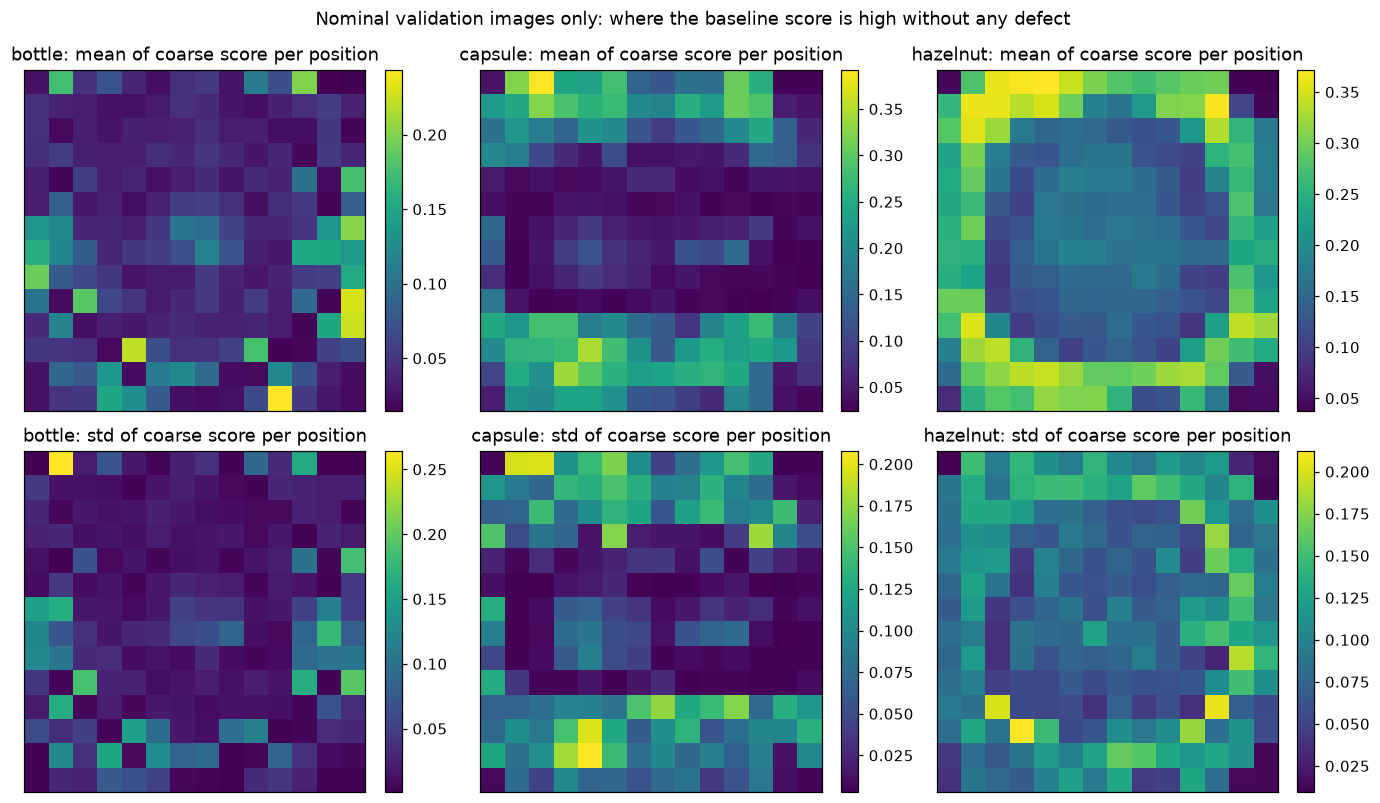

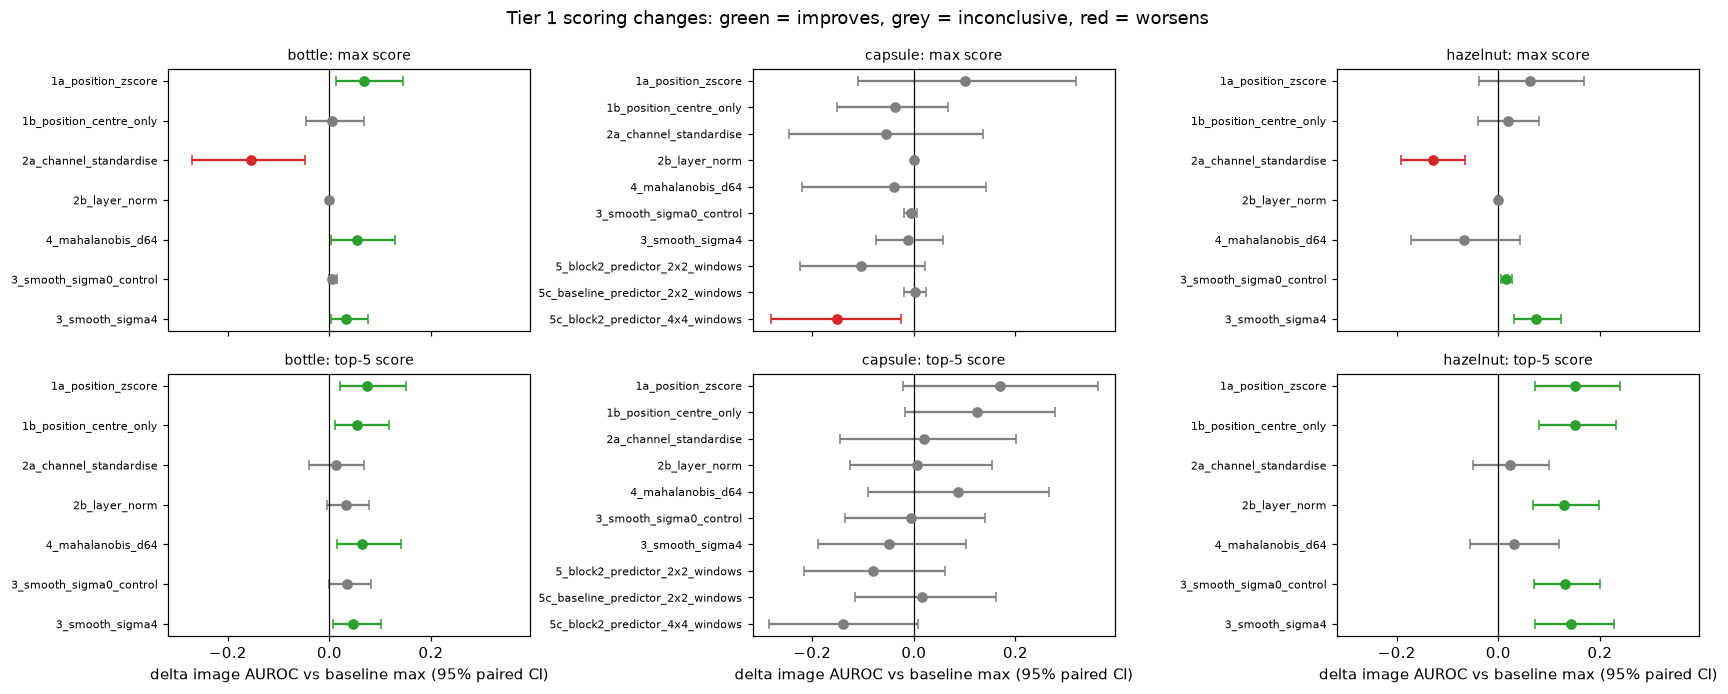

In [16]:
primary = boot_df[(boot_df.role == 'primary') & (boot_df.reference == 'baseline, max score')]
summary_table = primary.groupby(['item', 'variant', 'image_score', 'verdict']).category.apply(lambda s: ', '.join(s)).unstack('verdict').fillna('')
display(summary_table)

fig, axes = plt.subplots(2, len(CATEGORIES), figsize=(5.2 * len(CATEGORIES), 6.4), sharex=True)
colors = {'improves': '#2CA02C', 'worsens': '#D62728', 'inconclusive (CI contains 0)': '#7F7F7F'}
for col, category in enumerate(CATEGORIES):
    for row, score_label in enumerate(('max', f'top-{TOP_K}')):
        view = boot_df[(boot_df.category == category) & (boot_df.image_score == score_label)
                       & (boot_df.reference == 'baseline, max score') & (boot_df.variant != 'baseline')]
        view = view[view.role.isin(['primary', 'ablation', 'control'])].reset_index(drop=True)
        ax = axes[row, col]
        for y, r in view.iterrows():
            ax.errorbar(r.delta_image_auroc, y, xerr=[[r.delta_image_auroc - r.ci95_low], [r.ci95_high - r.delta_image_auroc]],
                        fmt='o', color=colors[r.verdict], capsize=3)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_yticks(range(len(view)))
        ax.set_yticklabels(view.variant, fontsize=7)
        ax.invert_yaxis()
        ax.set_title(f'{category}: {score_label} score', fontsize=9)
        if row == 1:
            ax.set_xlabel('delta image AUROC vs baseline max (95% paired CI)')
fig.suptitle('Tier 1 scoring changes: green = improves, grey = inconclusive, red = worsens')
fig.tight_layout()
plt.show()

## Save results

Everything is written under `results/improvements/tier1/` together with the declared settings, the fitted-statistics provenance and the baseline-reproduction checks. Existing files are never replaced unless `OVERWRITE = True`.

In [17]:
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()] + list(FIGURE_ROOT.glob('*.png'))
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)))

metrics_df.to_csv(OUTPUT_ROOT / 'variant_metrics.csv', index=False)
boot_df.to_csv(OUTPUT_ROOT / 'bootstrap_deltas.csv', index=False)
pd.concat([
    maha_df.assign(table='mahalanobis_split_half'),
    block2_val_df.assign(table='block2_nominal_validation'),
    pd.DataFrame(channel_rows).assign(table='channel_outliers_train'),
], ignore_index=True).to_csv(OUTPUT_ROOT / 'nominal_validation_diagnostics.csv', index=False)
position_df.to_csv(OUTPUT_ROOT / 'position_bias.csv', index=False)
fig.savefig(FIGURE_ROOT / 'tier1_delta_forest.png', dpi=150, bbox_inches='tight')
POSITION_FIG.savefig(FIGURE_ROOT / 'position_bias_maps.png', dpi=150, bbox_inches='tight')

summary = {
    'declared_before_test': DECLARED,
    'encoder_sha256': ENCODER_SHA256,
    'predictor_set': 'baseline (checkpoints/predictors) + capsule 2x2-block (checkpoints/predictors_block2)',
    'predictor_provenance_status': {c: PROVENANCE[c]['status'] for c in CATEGORIES},
    'block2_split_check': {k: v for k, v in block2_split_check.items() if k != 'training_config'},
    'block2_training_config': block2_split_check['training_config'],
    'images': {
        c: {'train': len(TRAIN_DATASETS[c]), 'val': len(VAL_DATASETS[c]), 'test': len(TEST_DATASETS[c])} for c in CATEGORIES
    },
    'statistics_provenance': {
        'item1_position_zscore': 'nominal validation images only',
        'item2_channel_standardisation': 'nominal training latents only',
        'item4_mahalanobis': 'nominal validation images only',
    },
    'baseline_reproduces_results_calibration': BASELINE_REPRODUCED,
    'bootstrap_matches_notebook_04': BOOTSTRAP_MATCHES_NB04,
    'masks_per_image_identical_for_items_1_to_4': all(
        np.array_equal(VARIANTS[c][n]['work'], VARIANTS[c]['baseline']['work'])
        for c in CATEGORIES for n in VARIANTS[c] if VARIANTS[c][n]['item'] in {'1', '2', '3', '4'}
    ),
    'verdict_counts_primary_vs_baseline_max': primary.groupby('verdict').size().to_dict(),
    'tau_and_all_settings_chosen_from': 'declared up front or nominal train/validation data only',
    'test_used_for_selection': False,
}
(OUTPUT_ROOT / 'tier1_summary.json').write_text(json.dumps(summary, indent=2, sort_keys=True, default=str), encoding='utf-8')
print(f'Saved results to {OUTPUT_ROOT}')

Saved results to C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\tier1


## What you can and cannot say

Read the paired-bootstrap table first. It is the honest scoreboard.

**You can say**

* Which fitted statistics came from which nominal split (all of them from train or validation images, none from test).
* For each Tier 1 item and each category, the change in image AUROC with its 95% paired-bootstrap interval, and the point change in pixel AUROC and AUPRO.
* That items 1-4 evaluate exactly the baseline's windows (`masks/image` is unchanged), so compute is unchanged.
* That the 2x2-block predictor with 2x2 windows costs 49 coarse masks per image instead of 16 (the extra masks are the price of item 5).

**You cannot say**

* That a change "improves" detection when its interval contains 0 (the verdict says `inconclusive`).
* That the best-looking `sensitivity` row is the best setting. Those rows are for understanding; picking one from the test numbers would be tuning on the test set.
* That a pixel-level difference is significant: pixel AUROC and AUPRO have no interval here.
* Anything about other categories, other seeds, or predictors trained differently. With 83-132 test images per category, differences of a few AUROC points are within noise.
* That the nominal-validation discrepancy of the 2x2-block predictor predicts its detection performance.

**Next steps in the plan** (not done here): item 12 (synthetic-anomaly validation set, so that later settings can be chosen legitimately), then the item 6 diagnostic and item 7 zero-shot evaluation.